# Time series Classification

In [95]:
import sys
import os
PROJECT_ROOT = os.path.abspath(os.path.join(os.getcwd(), "../.."))
if PROJECT_ROOT not in sys.path:
    sys.path.insert(0, PROJECT_ROOT)
import pandas as pd
from src.utils.labels_binary_classification import generate_ischemic_labels
import numpy as np
from tslearn.shapelets import LearningShapelets
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from tslearn.shapelets import grabocka_params_to_shapelet_size_dict
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier


import matplotlib.pyplot as plt

from tslearn.preprocessing import TimeSeriesScalerMinMax

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    RocCurveDisplay
)

import stumpy

PROFILE_PATH = "../../data/processed/time_series_features.pkl"
DIAG_PATH = "../../data/raw/heart_diagnoses_1.csv"
LABELS_OUT = "../../data/processed/subject_to_labels_ischemic.csv"

df = pd.read_pickle(PROFILE_PATH)
df["subject_id"] = df["subject_id"].astype(str)

print("Patient profile loaded:", df.shape)

labels_df = generate_ischemic_labels(
    diagnoses_path=DIAG_PATH,
    output_path=LABELS_OUT
)
labels_df["subject_id"] = labels_df["subject_id"].astype(str)  # Ensure matching types

print("Labels generated:")
print(labels_df["label_ischemic"].value_counts())

# Remove ICD-derived features to avoid data leakage
ICD_MACRO_COLS = [
    "ACS_acute_ischemic",
    "Chronic_ischemic",
    "Heart_failure",
    "Valvular_nonrheumatic",
    "Myocarditis_or_cardiomyopathy",
    "Pericardial_disease",
    "Endocarditis",
    "Cardiac_arrest",
    "Arrhythmias_or_conduction",
]

clf_df = df.drop(columns=[c for c in ICD_MACRO_COLS if c in df.columns])

# Merge labels with features
clf_df = clf_df.merge(labels_df[["subject_id", "label_ischemic"]], on="subject_id", how="inner")

print("Final classification dataset:", clf_df.shape)
print(f"Label distribution:\n{clf_df['label_ischemic'].value_counts()}")

# Convert 'gender' to boolean 
clf_df['gender'] = clf_df['gender'].map({'M': 1, 'F': 0})

clf_df

Patient profile loaded: (1276, 14)
Labels generated:
label_ischemic
0    2374
1    2018
Name: count, dtype: int64
Final classification dataset: (1276, 15)
Label distribution:
label_ischemic
0    656
1    620
Name: count, dtype: int64


,subject_id,Heart_Rate,SDNN,RMSSD,pNN50,r_amplitude,qrs_duration_ms,template_kurtosis,smoothed_II,hadm_id,icd_code,long_title,gender,age,label_ischemic
0,10000980,76.962545,301.422996,348.812589,90.000000,3.558921,30.0,7.847749,"[0.09426918915363115, 0.13102694114089175, 0.1...",29654838,I50,Heart failure,0,75,1
1,10000980,76.962545,301.422996,348.812589,90.000000,3.558921,30.0,7.847749,"[0.09426918915363115, 0.13102694114089175, 0.1...",26913865,I21,Acute myocardial infarction,0,75,1
2,10004457,99.645704,5.926534,5.042675,0.000000,4.066891,28.0,11.742084,"[-0.17110649065693853, -0.17573695129669084, -...",28723315,I35,Nonrheumatic aortic valve disorders,1,66,0
3,10007058,58.351568,26.391286,31.505102,12.500000,2.080999,20.0,12.254084,"[0.027518288072748195, 0.035552667670175564, 0...",22954658,I21,Acute myocardial infarction,1,48,1
4,10018684,133.185350,97.416901,141.930302,10.000000,0.630703,148.0,2.368135,"[-0.11601419637614092, -0.17089621947159478, -...",26649049,I48,Atrial fibrillation and flutter,1,48,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1271,19969326,122.107969,96.818393,131.834914,63.157895,2.991135,28.0,4.771796,"[0.13251892048399905, 0.05307477665610459, -0....",20407284,I48,Atrial fibrillation and flutter,0,71,0
1272,19969991,94.958173,32.510015,55.782545,21.428571,1.056046,630.0,2.650678,"[0.25272275112600523, 0.2679980919617599, 0.27...",22950880,I48,Atrial fibrillation and flutter,0,62,0
1273,19970101,81.692501,41.882008,36.909800,15.384615,2.005878,94.0,0.481158,"[-0.035485507247157884, -0.02030367311639871, ...",28958051,I21,Acute myocardial infarction,1,87,1
1274,19985259,71.973828,163.398453,292.063692,36.363636,3.763765,24.0,13.358984,"[-0.12257340203449632, -0.15569189154435265, -...",23988340,I47,Paroxysmal tachycardia,1,70,0


In [96]:
# Evaluation: train vs test

def evaluate_binary(model, Xtr, ytr, Xte, yte):
    # predizioni (0/1)
    ytr_pred = model.predict(Xtr)
    yte_pred = model.predict(Xte)

    # probabilità (serve per ROC-AUC)
    ytr_proba = model.predict_proba(Xtr)[:, 1]
    yte_proba = model.predict_proba(Xte)[:, 1]

    results = {
        "train_accuracy": accuracy_score(ytr, ytr_pred),
        "test_accuracy": accuracy_score(yte, yte_pred),
        "train_balanced_accuracy": balanced_accuracy_score(ytr, ytr_pred),
        "test_balanced_accuracy": balanced_accuracy_score(yte, yte_pred),
        "train_precision": precision_score(ytr, ytr_pred),
        "test_precision": precision_score(yte, yte_pred),
        "train_recall": recall_score(ytr, ytr_pred),
        "test_recall": recall_score(yte, yte_pred),
        "train_f1": f1_score(ytr, ytr_pred),
        "test_f1": f1_score(yte, yte_pred),
        "train_roc_auc": roc_auc_score(ytr, ytr_proba),
        "test_roc_auc": roc_auc_score(yte, yte_proba),
    }
    return results, (ytr_pred, yte_pred, ytr_proba, yte_proba)


## Features classification

### Logistic Regression

In [97]:


TARGET = "label_ischemic"
DROP_COLS_METADATA = ['subject_id', 'hadm_id', 'smoothed_II', 'long_title', 'icd_code', 'pNN50', 'SDNN']

# Fix: flatten the list so all columns are passed as a single list
X = clf_df.drop(columns=[TARGET] + DROP_COLS_METADATA)
y = clf_df[TARGET].astype(int)

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.30, #divido il dataset in 70% training e 30% test
    stratify=y,
    random_state=42
)

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

print("Train:", X_train.shape, " Test:", X_test.shape)
print("Train label distribution:\n", y_train.value_counts(normalize=True))
print("Test  label distribution:\n", y_test.value_counts(normalize=True))

Train: (893, 7)  Test: (383, 7)
Train label distribution:
 label_ischemic
0    0.513998
1    0.486002
Name: proportion, dtype: float64
Test  label distribution:
 label_ischemic
0    0.51436
1    0.48564
Name: proportion, dtype: float64


In [98]:

lr_clf = Pipeline(steps=[
    ("model", LogisticRegression(
        penalty="l2",          # regolarizzazione L2: 2 regularization: penalizza coefficienti grandi, riduce l’overfitting, è stabile numericamente
        C=1.0,                 # forza regolarizzazione (più piccolo = più reg)
        solver="lbfgs",
        max_iter=2000,
        class_weight="balanced",
        random_state=42
    ))
])

lr_clf.fit(X_train, y_train)

/Users/tommy/miniconda3/envs/DA4DH/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators ` for more details.","[('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing `.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add a L2 penalty term and it is the default choice;- `'l1'`: add a L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'` and `l1_ratio` set to any float between 0 and 1 for `'penalty='elasticnet'`.",'l2'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation `) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifie

In [99]:
lr_results, (y_train_pred, y_test_pred, y_train_proba, y_test_proba) = evaluate_binary(
    lr_clf, X_train, y_train, X_test, y_test
)

pd.Series(lr_results).sort_index()

test_accuracy              0.537859
test_balanced_accuracy     0.539654
test_f1                    0.558603
test_precision             0.520930
test_recall                0.602151
test_roc_auc               0.531548
train_accuracy             0.567749
train_balanced_accuracy    0.567975
train_f1                   0.564334
train_precision            0.553097
train_recall               0.576037
train_roc_auc              0.592829
dtype: float64

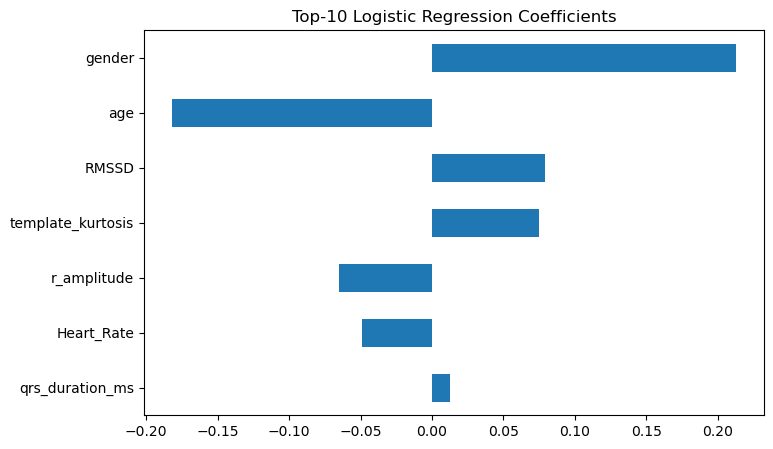

In [100]:
coef = lr_clf.named_steps["model"].coef_[0]
coef_df = (
    pd.Series(coef, index=X.columns)
    .sort_values(key=np.abs, ascending=False)
)

coef_df.head(10)
plt.figure(figsize=(8, 5))
coef_df.head(10).plot(kind="barh")
plt.title("Top-10 Logistic Regression Coefficients")
plt.gca().invert_yaxis()
plt.show()



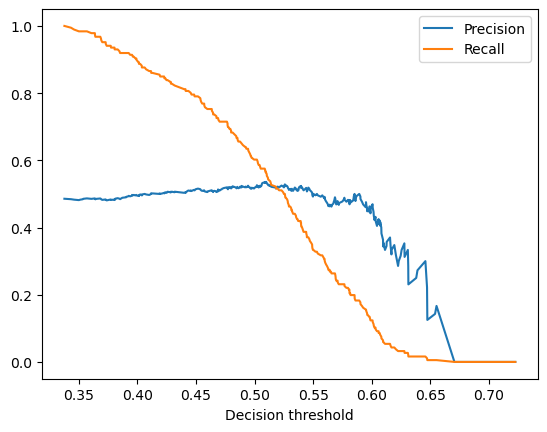

In [101]:
from sklearn.metrics import precision_recall_curve

prec, rec, thr = precision_recall_curve(y_test, y_test_proba)

plt.plot(thr, prec[:-1], label="Precision")
plt.plot(thr, rec[:-1], label="Recall")
plt.xlabel("Decision threshold")
plt.legend()
plt.show()


In [102]:
from sklearn.model_selection import cross_val_score

cv_scores_lr = cross_val_score(
    lr_clf,
    X_train,
    y_train,
    cv=5,
    scoring="balanced_accuracy"
)

print("Logistic Regression - 5-fold CV balanced accuracy")
print(f"Mean = {cv_scores_lr.mean():.3f}")
print(f"Std  = {cv_scores_lr.std():.3f}")


Logistic Regression - 5-fold CV balanced accuracy
Mean = 0.553
Std  = 0.036


/Users/tommy/miniconda3/envs/DA4DH/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(
/Users/tommy/miniconda3/envs/DA4DH/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(
/Users/tommy/miniconda3/envs/DA4DH/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and w

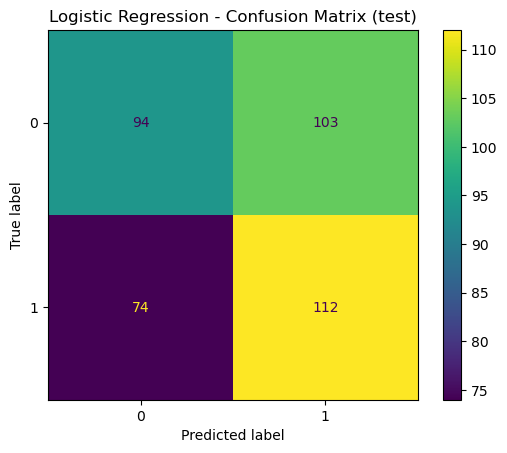


Classification report (test):
                  precision    recall  f1-score   support

Non-ischemic (0)       0.56      0.48      0.52       197
    Ischemic (1)       0.52      0.60      0.56       186

        accuracy                           0.54       383
       macro avg       0.54      0.54      0.54       383
    weighted avg       0.54      0.54      0.54       383



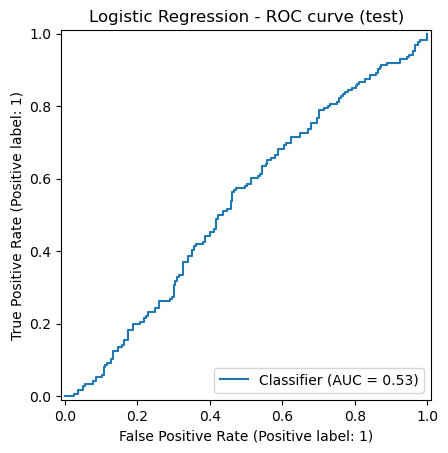

In [103]:
# Confusion matrix (test)
cm = confusion_matrix(y_test, y_test_pred, labels=[0, 1])
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=[0, 1])
disp.plot()
plt.title("Logistic Regression - Confusion Matrix (test)")
plt.show()

print("\nClassification report (test):")
print(classification_report(y_test, y_test_pred, target_names=["Non-ischemic (0)", "Ischemic (1)"]))

# ROC curve (test)

RocCurveDisplay.from_predictions(y_test, y_test_proba)
plt.title("Logistic Regression - ROC curve (test)")
plt.show()


## Support Vector Machine

In [104]:
from sklearn.svm import SVC

# Create the SVM classifier
svm_clf = SVC(
    kernel="rbf",          # Radial Basis Function kernel
    C=1.0,                 # Regularization parameter
    gamma="scale",        # Kernel coefficient
    probability=True,     # Enable probability estimates
    class_weight="balanced",
    random_state=42
)

svm_clf.fit(X_train, y_train)

svm_results, (y_train_pred_svm, y_test_pred_svm, y_train_proba_svm, y_test_proba_svm) = evaluate_binary(
    svm_clf, X_train, y_train, X_test, y_test
)

pd.Series(svm_results).sort_index()

test_accuracy              0.545692
test_balanced_accuracy     0.546818
test_f1                    0.556122
test_precision             0.529126
test_recall                0.586022
test_roc_auc               0.565089
train_accuracy             0.608063
train_balanced_accuracy    0.608948
train_f1                   0.613687
train_precision            0.588983
train_recall               0.640553
train_roc_auc              0.653263
dtype: float64

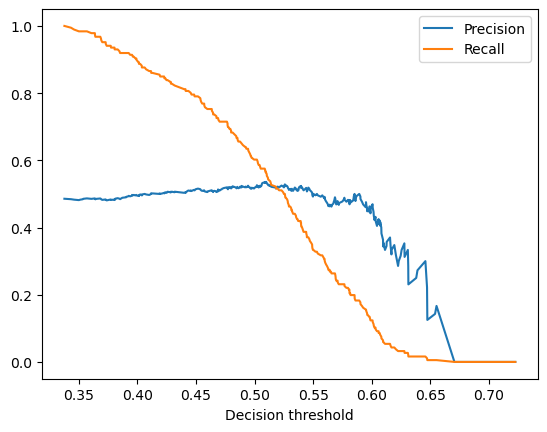

In [105]:
prec, rec, thr = precision_recall_curve(y_test, y_test_proba)

plt.plot(thr, prec[:-1], label="Precision")
plt.plot(thr, rec[:-1], label="Recall")
plt.xlabel("Decision threshold")
plt.legend()
plt.show()

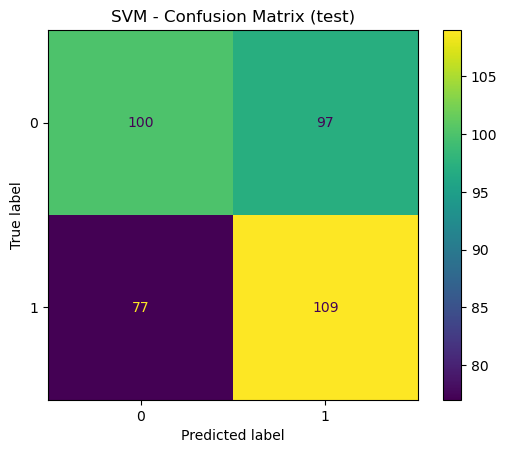

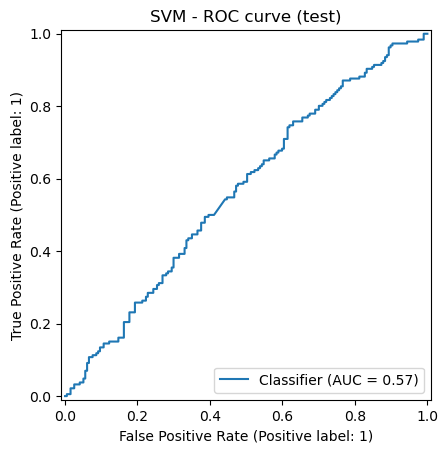

In [106]:
# Plot the confusion matrix for SVM (test)
cm_svm = confusion_matrix(y_test, y_test_pred_svm, labels=[0, 1])
disp_svm = ConfusionMatrixDisplay(confusion_matrix=cm_svm, display_labels=[0, 1])
disp_svm.plot()
plt.title("SVM - Confusion Matrix (test)")
plt.show()

# PLot the ROC curve for SVM (test)
RocCurveDisplay.from_predictions(y_test, y_test_proba_svm)
plt.title("SVM - ROC curve (test)")
plt.show()

In [107]:
cv_scores_svm = cross_val_score(
    svm_clf,
    X_train,
    y_train,
    cv=5,
    scoring="balanced_accuracy"
)

print("Logistic Regression - 5-fold CV balanced accuracy")
print(f"Mean = {cv_scores_lr.mean():.3f}")
print(f"Std  = {cv_scores_lr.std():.3f}")

Logistic Regression - 5-fold CV balanced accuracy
Mean = 0.553
Std  = 0.036


## Gradient boosting Classifier

In [108]:
from sklearn.ensemble import GradientBoostingClassifier
gb_clf = GradientBoostingClassifier(
    n_estimators=300,       
    learning_rate=0.01,    
    max_depth=6,              
    random_state=42
)

gb_clf.fit(X_train, y_train)

gb_results, (gb_y_train_pred, gb_y_test_pred, gb_y_train_proba, gb_y_test_proba) = evaluate_binary(
    gb_clf, X_train, y_train, X_test, y_test
)

print(pd.Series(gb_results).sort_index())



test_accuracy              0.603133
test_balanced_accuracy     0.602205
test_f1                    0.582418
test_precision             0.595506
test_recall                0.569892
test_roc_auc               0.619808
train_accuracy             0.851064
train_balanced_accuracy    0.850790
train_f1                   0.845886
train_precision            0.850816
train_recall               0.841014
train_roc_auc              0.932203
dtype: float64


In [109]:
cv_scores_gb = cross_val_score(
    gb_clf, X_train, y_train,
    cv=5,
    scoring="balanced_accuracy"
)
print("GB - 5-fold CV balanced accuracy")
print(f"Mean = {cv_scores_gb.mean():.3f} | Std = {cv_scores_gb.std():.3f}")

GB - 5-fold CV balanced accuracy
Mean = 0.551 | Std = 0.018


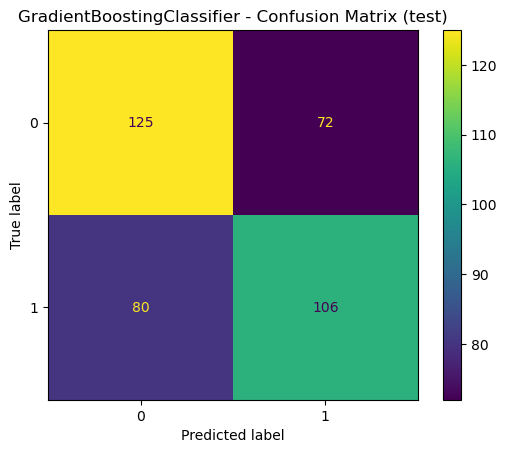

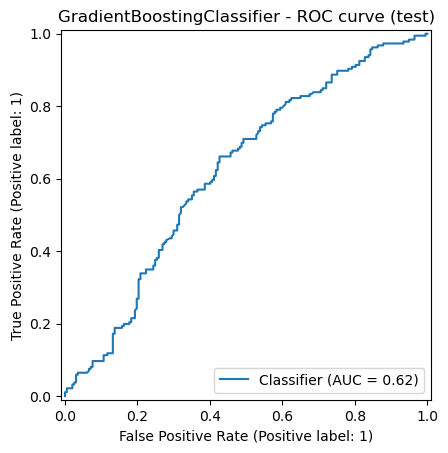

In [110]:
# Confusion matrix (test)
cm_rf = confusion_matrix(y_test, gb_y_test_pred, labels=[0, 1])
disp = ConfusionMatrixDisplay(confusion_matrix=cm_rf, display_labels=[0, 1])
disp.plot()
plt.title("GradientBoostingClassifier - Confusion Matrix (test)")
plt.show()

# ROC curve (test)
RocCurveDisplay.from_predictions(y_test, gb_y_test_proba)
plt.title("GradientBoostingClassifier - ROC curve (test)")
plt.show()

## Random Forest

In [111]:
from sklearn.ensemble import RandomForestClassifier

rf_clf = RandomForestClassifier(
    n_estimators=30, #un numero moderato di alberi è sufficiente per ridurre la varianza rispetto a un singolo decision tree.
    criterion="gini", 
    max_features=3, #Questo introduce randomizzazione tra gli alberi, riducendo la correlazione e migliorando la generalizzazione
    max_depth=4, #Limita la profondità degli alberi per prevenire overfitting,
    min_samples_split=2, # Valore standard che consente agli alberi di crescere senza eccessive restrizioni.
    min_samples_leaf=8, # Impedisce foglie troppo piccole → predizioni più stabili e generalizzabili.
    bootstrap=True,  
    class_weight="balanced",
    random_state=42
)

In [112]:
from sklearn.model_selection import RandomizedSearchCV
from scipy.stats import randint

param_dist = {
    "n_estimators": [30, 50, 100],
    "max_depth": [2, 4, 6, 8, None],
    "max_features": [2, 3, "sqrt"],
    "min_samples_split": randint(2, 20),
    "min_samples_leaf": randint(5, 20),
    "bootstrap": [True],
    "criterion": ["gini", "entropy"],
    "class_weight": ["balanced", None]
}

In [113]:
rf_base = RandomForestClassifier(random_state=42)

rf_search = RandomizedSearchCV(
    estimator=rf_base,
    param_distributions=param_dist,
    n_iter=30,
    scoring="balanced_accuracy",
    cv=5,
    n_jobs=-1,
    random_state=42
)

rf_search.fit(X_train, y_train)

print("Best parameters found:")
print(rf_search.best_params_)

/Users/tommy/miniconda3/envs/DA4DH/lib/python3.13/multiprocessing/queues.py:120: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  return _ForkingPickler.loads(res)
/Users/tommy/miniconda3/envs/DA4DH/lib/python3.13/multiprocessing/queues.py:120: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  return _ForkingPickler.loads(res)
/Users/tommy/miniconda3/envs/DA4DH/lib/python3.13/multiprocessing/queues.py:120: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from usi

Best parameters found:
{'bootstrap': True, 'class_weight': None, 'criterion': 'entropy', 'max_depth': 8, 'max_features': 2, 'min_samples_leaf': 5, 'min_samples_split': 13, 'n_estimators': 50}


In [114]:
rf_best = rf_search.best_estimator_

rf_best.fit(X_train, y_train)

rf_best_results, (rfb_y_train_pred, rfb_y_test_pred,
                  rfb_y_train_proba, rfb_y_test_proba) = evaluate_binary(
    rf_best, X_train, y_train, X_test, y_test
)

pd.Series(rf_best_results).sort_index()


test_accuracy              0.579634
test_balanced_accuracy     0.578012
test_f1                    0.546479
test_precision             0.573964
test_recall                0.521505
test_roc_auc               0.589133
train_accuracy             0.773796
train_balanced_accuracy    0.772552
train_f1                   0.757794
train_precision            0.790000
train_recall               0.728111
train_roc_auc              0.855401
dtype: float64

In [115]:
# comparison with baseline RF and RF with tuned hyperparameters (RandomizedSearchCV)
rf_baseline = rf_clf  # il modello con parametri fissi
rf_baseline.fit(X_train, y_train)

rf_base_results, _ = evaluate_binary(
    rf_baseline, X_train, y_train, X_test, y_test
)

comparison_rf = pd.DataFrame({
    "Baseline RF": rf_base_results,
    "Tuned RF": rf_best_results
})

comparison_rf.sort_index()


,Baseline RF,Tuned RF
test_accuracy,0.527415,0.579634
test_balanced_accuracy,0.528001,0.578012
test_f1,0.529870,0.546479
test_precision,0.512563,0.573964
test_recall,0.548387,0.521505
test_roc_auc,0.559754,0.589133
train_accuracy,0.668533,0.773796
train_balanced_accuracy,0.669591,0.772552
train_f1,0.674725,0.757794
train_precision,0.644958,0.790000


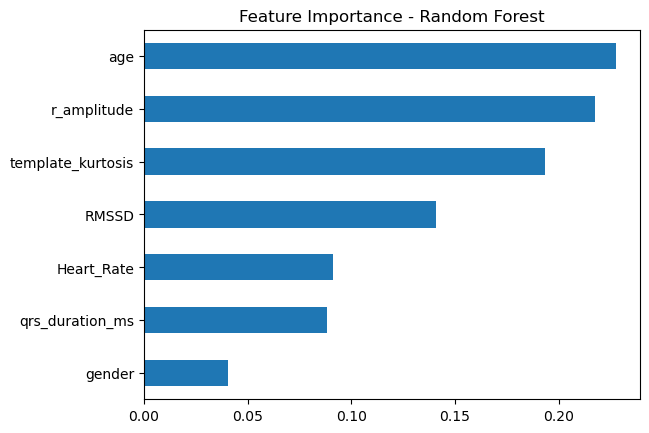

In [116]:
# Feature Importance for Random Forest
feat_importances = pd.Series(rf_best.feature_importances_, index=X.columns)
feat_importances.nlargest(10).plot(kind='barh', title='Feature Importance - Random Forest')
plt.gca().invert_yaxis()
plt.show()

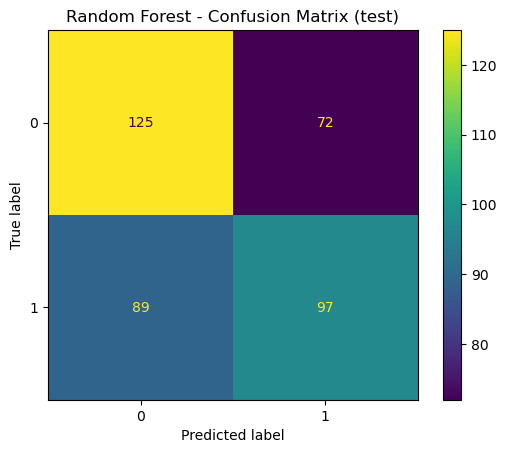


Classification report (test):
                  precision    recall  f1-score   support

Non-ischemic (0)       0.58      0.63      0.61       197
    Ischemic (1)       0.57      0.52      0.55       186

        accuracy                           0.58       383
       macro avg       0.58      0.58      0.58       383
    weighted avg       0.58      0.58      0.58       383



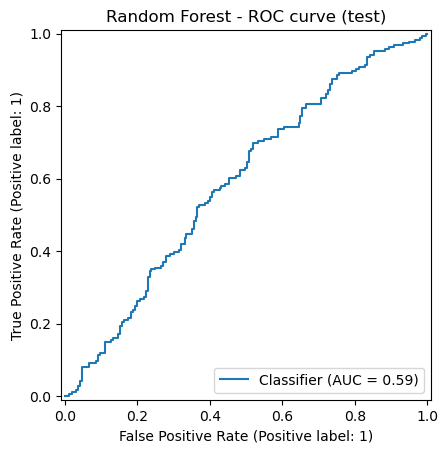

In [117]:
# Confusion matrix (test)
cm_rf = confusion_matrix(y_test, rfb_y_test_pred, labels=[0, 1])
disp = ConfusionMatrixDisplay(confusion_matrix=cm_rf, display_labels=[0, 1])
disp.plot()
plt.title("Random Forest - Confusion Matrix (test)")
plt.show()

print("\nClassification report (test):")
print(classification_report(
    y_test, rfb_y_test_pred,
    target_names=["Non-ischemic (0)", "Ischemic (1)"]
))

# ROC curve (test)
RocCurveDisplay.from_predictions(y_test, rfb_y_test_proba)
plt.title("Random Forest - ROC curve (test)")
plt.show()


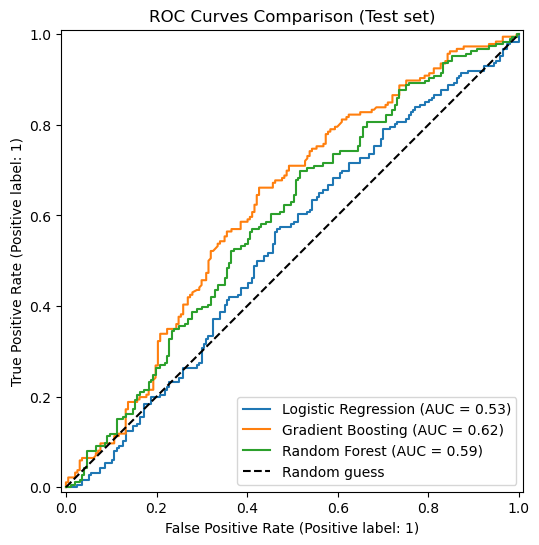

In [118]:

fig, ax = plt.subplots(figsize=(7, 6))

RocCurveDisplay.from_predictions(
    y_test, y_test_proba,
    name="Logistic Regression",
    ax=ax
)

RocCurveDisplay.from_predictions(
    y_test, gb_y_test_proba,
    name="Gradient Boosting",
    ax=ax
)

RocCurveDisplay.from_predictions(
    y_test, rfb_y_test_proba,
    name="Random Forest",
    ax=ax
)

ax.plot([0, 1], [0, 1], "k--", label="Random guess")
ax.set_title("ROC Curves Comparison (Test set)")
ax.legend()
plt.show()


## Time series motifs

In [119]:
from scipy.stats import skew
# Get the profile matrices of each patient
fs = 500
profile_matrices = []
patient_beats = {}
patient_anomalies = {}
features_list = []
# Use STUMPY to compute the matrix profile
m = int(0.8 * fs) 

for subject_id, data in df.groupby('subject_id'):
    signal = np.array(data['smoothed_II'].iloc[0])

    if len(signal) < m:
        print(f"Signal for subject {subject_id} is shorter than subsequence length m={m}. Skipping.")
        continue

    profile = stumpy.stump(signal, m)
    profile_matrices.append(profile)

    # Get the top motifs
    motif_distances, motif_indices = stumpy.motifs(signal, profile[:, 0], max_motifs=3, min_neighbors=3)
    patient_beats[subject_id] = motif_indices[0]

    # Anomaly detection using matrix profile (top 3 discords)
    discord_indices = np.argpartition(profile[:, 0], -3)[-3:]
    # Sort by anomaly score descending
    discord_indices = discord_indices[np.argsort(profile[discord_indices, 0])[::-1]]
    discord_scores = profile[discord_indices, 0]
    patient_anomalies[subject_id] = list(zip(discord_indices, discord_scores))

    # Features Extraction for classification
    P = profile[:, 0]
    I = profile[:, 1]

    P = np.asarray(P, dtype=np.float64)

    features = {
            'subject_id': subject_id,
            
            # --- Morphology Features (Profile P) ---
            'mp_min': np.min(P),       # Best Motif
            'mp_max': np.max(P),       # Worst Anomaly
            'mp_mean': np.mean(P),     # Average noise/irregularity
            'mp_std': np.std(P),       # Variance in morphology
            'mp_skew': skew(P),        # Is the profile lopsided?
            
            # --- Anomaly Count ---
            # Count how many segments are "very different" 
            'num_anomalies': np.sum(P > (np.mean(P) + 2*np.std(P))),
            
            # --- Rhythm Features (Indices I) ---
            # Calculate absolute distance to nearest neighbor
            # "How far do I have to look to find a match?"
            'avg_neighbor_dist': np.mean(np.abs(I - np.arange(len(I))))
        }
        
    features_list.append(features)




profile_matrices = np.array(profile_matrices)
profile_matrices.shape
    

(1184, 4601, 4)

In [120]:
features_df = pd.DataFrame(features_list)
# Add the ischemic labels
features_df = features_df.merge(
    labels_df[["subject_id", "label_ischemic"]],
    on="subject_id",
    how="inner"
)

features_df

,subject_id,mp_min,mp_max,mp_mean,mp_std,mp_skew,num_anomalies,avg_neighbor_dist,label_ischemic
0,10000980,1.586689,19.322014,3.394246,2.117322,2.673722,321,2321.0725929145838,1
1,10004457,0.499277,2.257932,0.930091,0.343071,0.977364,385,1510.0765051075853,0
2,10007058,1.553935,11.638373,3.252670,2.034702,1.758590,263,2103.8289502282114,1
3,10018684,3.759811,11.682279,7.247383,1.432389,-0.034160,97,1221.1499673983917,0
4,10044096,1.798981,22.098755,5.599246,5.350026,1.728492,465,1637.9771788741577,1
...,...,...,...,...,...,...,...,...,...
1179,19969326,3.718932,19.707865,8.457579,3.601253,1.108715,302,1622.7215822647252,0
1180,19969991,4.816394,7.675361,6.097129,0.562875,0.037746,131,1393.4488154748967,0
1181,19970101,3.870637,11.208399,6.021021,1.701859,0.889655,177,1639.931101934362,1
1182,19985259,2.159769,17.785353,5.907382,4.187537,1.288965,304,1548.4355574875028,0


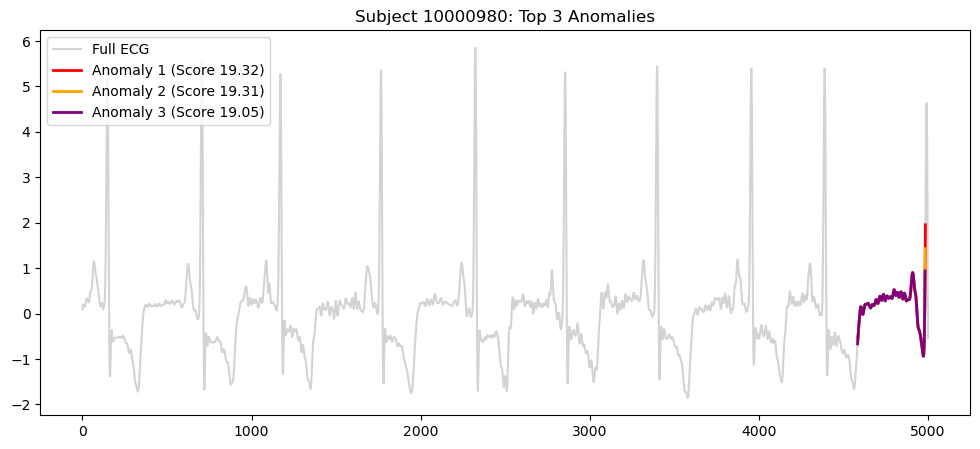

In [121]:
# Visualize the top 3 anomalies for one specific patient
subject_to_plot = list(patient_beats.keys())[0] # Just pick the first patient
discords = patient_anomalies[subject_to_plot]  # List of (idx, score) tuples

# Retrieve that patient's signal again for plotting
signal = df[df['subject_id'] == subject_to_plot]['smoothed_II'].iloc[0]

plt.figure(figsize=(12, 5))
plt.plot(signal, color='lightgray', label="Full ECG")

# Highlight the top 3 anomalies in different colors
colors = ['red', 'orange', 'purple']
for i, (idx, score) in enumerate(discords):
    plt.plot(range(idx, idx+m), signal[idx : idx+m], color=colors[i % len(colors)], linewidth=2, label=f"Anomaly {i+1} (Score {score:.2f})")

plt.title(f"Subject {subject_to_plot}: Top 3 Anomalies")
plt.legend()
plt.show()

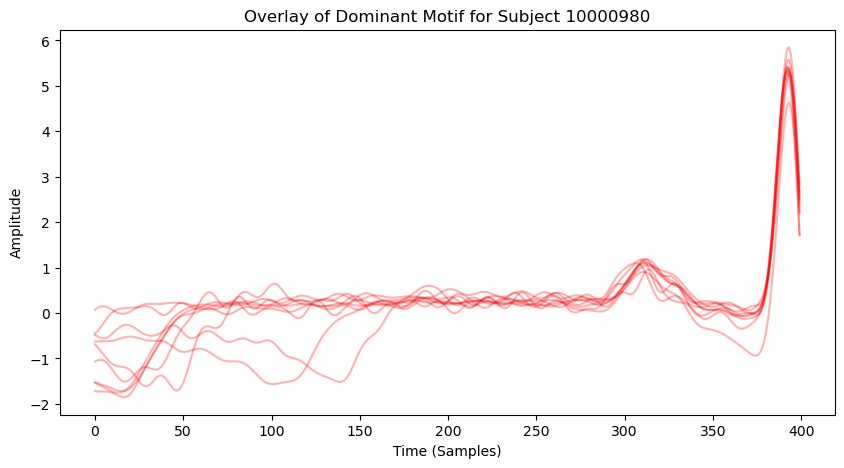

In [122]:
indices = patient_beats[subject_to_plot]
plt.figure(figsize=(10, 5))
plt.title(f"Overlay of Dominant Motif for Subject {subject_to_plot}")

# Loop through every index found and plot that segment
for idx in indices:
    # Ensure we don't go out of bounds
    if idx + m < len(signal):
        plt.plot(signal[idx : idx+m], color='red', alpha=0.3) # alpha makes them transparent

plt.xlabel("Time (Samples)")
plt.ylabel("Amplitude")
plt.show()

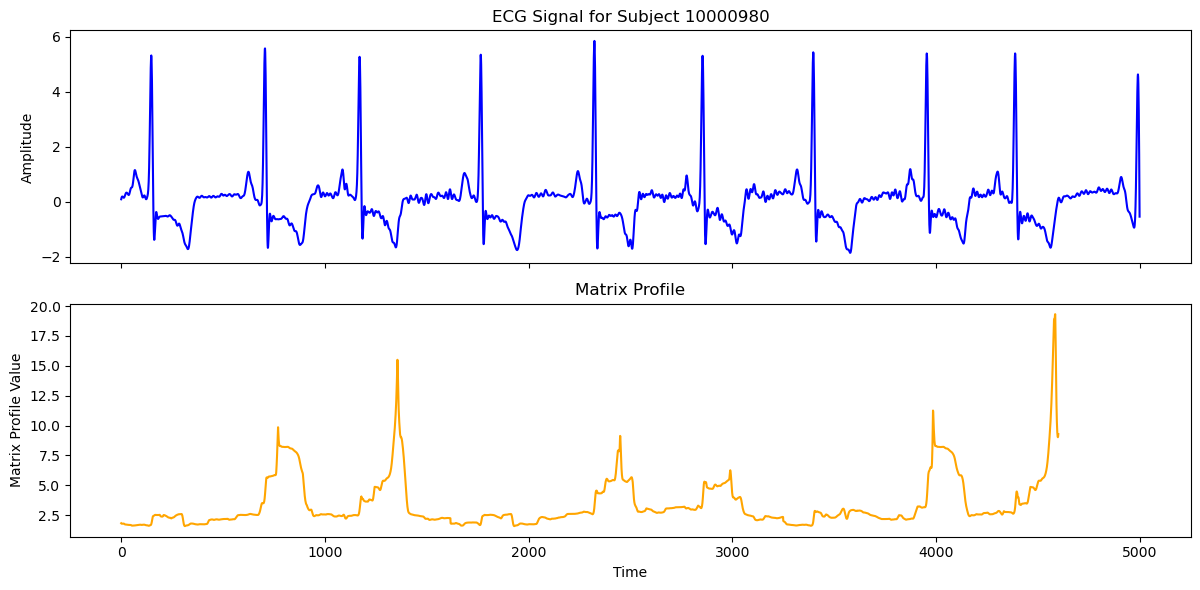

In [123]:
# plot the Matrix Profile directly under your ECG signal for the first patient
subject_id = df['subject_id'].iloc[0]
signal = np.array(df[df['subject_id'] == subject_id]['smoothed_II'].iloc[0])
profile = profile_matrices[0]
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 6), sharex=True)
ax1.plot(signal, color='blue')
ax1.set_title(f'ECG Signal for Subject {subject_id}')
ax1.set_ylabel('Amplitude')
ax2.plot(profile[:, 0], color='orange')
ax2.set_title('Matrix Profile')
ax2.set_ylabel('Matrix Profile Value')
ax2.set_xlabel('Time')
plt.tight_layout()
plt.show()

In [124]:
# Run a random forest classifier on the extracted features
TARGET = "label_ischemic"
X_feat = features_df.drop(columns=[TARGET, 'subject_id'])
y_feat = features_df[TARGET].astype(int)

# Split into train and test sets
Xf_train, Xf_test, yf_train, yf_test = train_test_split(
    X_feat, y_feat,
    test_size=0.30,
    stratify=y_feat,
    random_state=42
)

# Normalize features
scaler_feat = StandardScaler()
Xf_train = scaler_feat.fit_transform(Xf_train)
Xf_test = scaler_feat.transform(Xf_test)

rf_clf = RandomForestClassifier(
    n_estimators=30, #un numero moderato di alberi è sufficiente per ridurre la varianza rispetto a un singolo decision tree.
    criterion="gini", 
    max_features=3, #Questo introduce randomizzazione tra gli alberi, riducendo la correlazione e migliorando la generalizzazione
    max_depth=4, #Limita la profondità degli alberi per prevenire overfitting,
    min_samples_split=2, # Valore standard che consente agli alberi di crescere senza eccessive restrizioni.
    min_samples_leaf=8, # Impedisce foglie troppo piccole → predizioni più stabili e generalizzabili.
    bootstrap=True,  
    class_weight="balanced",
    random_state=42
)

In [125]:
from scipy.stats import randint
param_dist = {
    "n_estimators": [30, 50, 100],
    "max_depth": [2, 4, 6, 8, None],
    "max_features": [2, 3, "sqrt"],
    "min_samples_split": randint(2, 20),
    "min_samples_leaf": randint(5, 20),
    "bootstrap": [True],
    "criterion": ["gini", "entropy"],
    "class_weight": ["balanced", None]
}

In [126]:
from sklearn.model_selection import RandomizedSearchCV
rf_base = RandomForestClassifier(random_state=42)

rf_search = RandomizedSearchCV(
    estimator=rf_base,
    param_distributions=param_dist,
    n_iter=30,
    scoring="balanced_accuracy",
    cv=5,
    n_jobs=-1,
    random_state=42
)

rf_search.fit(Xf_train, yf_train)

print("Best parameters found:")
print(rf_search.best_params_)

Best parameters found:
{'bootstrap': True, 'class_weight': 'balanced', 'criterion': 'entropy', 'max_depth': 2, 'max_features': 3, 'min_samples_leaf': 5, 'min_samples_split': 17, 'n_estimators': 100}


In [127]:
rf_best = rf_search.best_estimator_

rf_best.fit(Xf_train, yf_train)

rf_best_results, (rfb_y_train_pred, rfb_y_test_pred,
                  rfb_y_train_proba, rfb_y_test_proba) = evaluate_binary(
    rf_best, Xf_train, yf_train, Xf_test, yf_test
)

pd.Series(rf_best_results).sort_index()

test_accuracy              0.522472
test_balanced_accuracy     0.524780
test_f1                    0.552632
test_precision             0.507246
test_recall                0.606936
test_roc_auc               0.530276
train_accuracy             0.595411
train_balanced_accuracy    0.597908
train_f1                   0.621469
train_precision            0.569358
train_recall               0.684080
train_roc_auc              0.647096
dtype: float64

In [128]:
# comparison with baseline RF and RF with tuned hyperparameters (RandomizedSearchCV)
rf_baseline = rf_clf  # il modello con parametri fissi
rf_baseline.fit(Xf_train, yf_train)

rf_base_results, _ = evaluate_binary(
    rf_baseline, Xf_train, yf_train, Xf_test, yf_test
)

comparison_rf = pd.DataFrame({
    "Baseline RF": rf_base_results,
    "Tuned RF": rf_best_results
})

comparison_rf.sort_index()


,Baseline RF,Tuned RF
test_accuracy,0.536517,0.522472
test_balanced_accuracy,0.537019,0.524780
test_f1,0.537815,0.552632
test_precision,0.521739,0.507246
test_recall,0.554913,0.606936
test_roc_auc,0.534382,0.530276
train_accuracy,0.641304,0.595411
train_balanced_accuracy,0.642860,0.597908
train_f1,0.653442,0.621469
train_precision,0.615385,0.569358


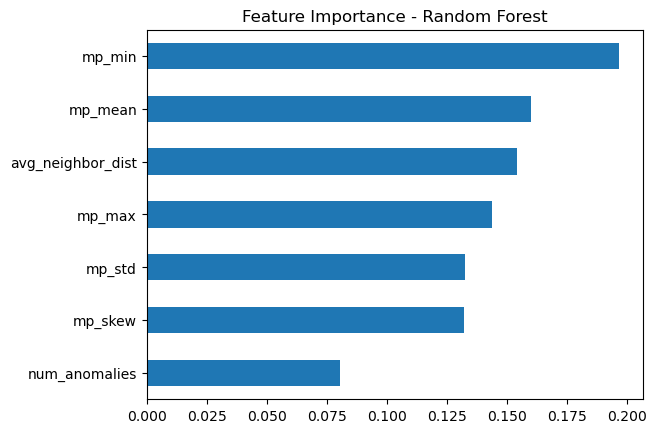

In [129]:
feat_importances = pd.Series(rf_best.feature_importances_, index=X_feat.columns)
feat_importances.nlargest(10).plot(kind='barh', title='Feature Importance - Random Forest')
plt.gca().invert_yaxis()
plt.show()

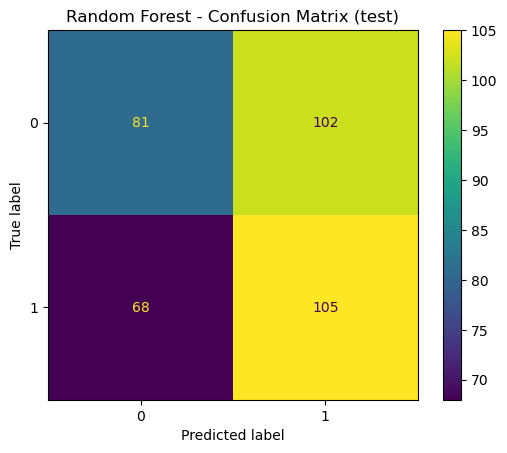


Classification report (test):
                  precision    recall  f1-score   support

Non-ischemic (0)       0.54      0.44      0.49       183
    Ischemic (1)       0.51      0.61      0.55       173

        accuracy                           0.52       356
       macro avg       0.53      0.52      0.52       356
    weighted avg       0.53      0.52      0.52       356



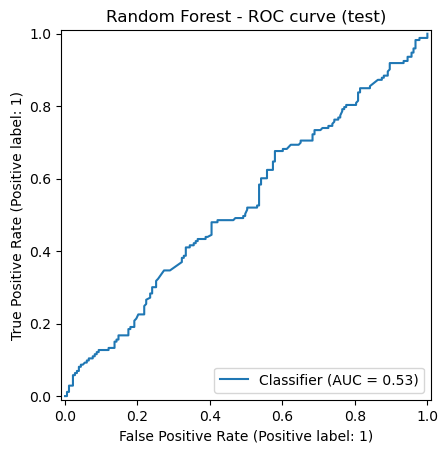

In [130]:
# Confusion matrix (test)
cm_rf = confusion_matrix(yf_test, rfb_y_test_pred, labels=[0, 1])
disp = ConfusionMatrixDisplay(confusion_matrix=cm_rf, display_labels=[0, 1])
disp.plot()
plt.title("Random Forest - Confusion Matrix (test)")
plt.show()

print("\nClassification report (test):")
print(classification_report(
    yf_test, rfb_y_test_pred,
    target_names=["Non-ischemic (0)", "Ischemic (1)"]
))

# ROC curve (test)
RocCurveDisplay.from_predictions(yf_test, rfb_y_test_proba)
plt.title("Random Forest - ROC curve (test)")
plt.show()

## Time series shaplets Classification

In [131]:
n_ts, ts_sz = clf_df.shape[0], clf_df['smoothed_II'].iloc[0].shape[0]
n_classes = clf_df['label_ischemic'].nunique()

In [132]:
from sklearn.model_selection import train_test_split
from tslearn.preprocessing import TimeSeriesScalerMeanVariance

X = np.array(clf_df['smoothed_II'].tolist())
y = np.array(clf_df['label_ischemic'].tolist())


X = X.reshape(X.shape[0], X.shape[1], 1)


print(f"Original Shape: {X.shape}")
X = X[:, :1500, :]
print(f"New Shape (Time Sliced): {X.shape}") 

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

Original Shape: (1276, 5000, 1)
New Shape (Time Sliced): (1276, 1500, 1)


In [133]:
# Scale the data
scaler = TimeSeriesScalerMeanVariance()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

In [138]:
# Get the sampling rate from the data
sampling_rate_hz = 500 
shapelet_sizes = {
    20: 50,    # QRS Complex (40ms: sharp, distinctive)
    50: 30,    # P-Wave (100ms: atrial depolarization)
    100: 20,   # T-Wave (200ms: ventricular repolarization)
    200: 10,   # QT Interval (400ms: complete ventricular cycle)
}

print("Optimized ECG Sizes:", shapelet_sizes)

Optimized ECG Sizes: {20: 50, 50: 30, 100: 20, 200: 10}


In [139]:
shp_clf = LearningShapelets(n_shapelets_per_size=shapelet_sizes,
                        optimizer="adam",
                        weight_regularizer=.01,
                        max_iter=2000,
                        verbose=1)

In [140]:
print(f"Min: {X_train.min()}, Max: {X_train.max()}")

Min: -4.351031723554947, Max: 8.238184090470984


In [141]:
# Fit the shapelet model
shp_clf.fit(X_train, y_train)

/Users/tommy/miniconda3/envs/DA4DH/lib/python3.13/site-packages/tslearn/shapelets/shapelets.py:492: FutureWarning: The default value for 'scale' is set to False in version 0.4 to ensure backward compatibility, but is likely to change in a future version.
  warnings.warn("The default value for 'scale' is set to False "
/Users/tommy/miniconda3/envs/DA4DH/lib/python3.13/site-packages/keras/src/layers/layer.py:970: UserWarning: Layer 'min_pooling_0' (of type GlobalMinPooling1D) was passed an input with a mask attached to it. However, this layer does not support masking and will therefore destroy the mask information. Downstream layers will not see the mask.
  warnings.warn(
/Users/tommy/miniconda3/envs/DA4DH/lib/python3.13/site-packages/keras/src/layers/layer.py:970: UserWarning: Layer 'min_pooling_1' (of type GlobalMinPooling1D) was passed an input with a mask attached to it. However, this layer does not support masking and will therefore destroy the mask information. Downstream layers wi

Epoch 1/2000


/Users/tommy/miniconda3/envs/DA4DH/lib/python3.13/site-packages/keras/src/layers/layer.py:970: UserWarning: Layer 'min_pooling_3' (of type GlobalMinPooling1D) was passed an input with a mask attached to it. However, this layer does not support masking and will therefore destroy the mask information. Downstream layers will not see the mask.
  warnings.warn(
/Users/tommy/miniconda3/envs/DA4DH/lib/python3.13/site-packages/keras/src/layers/layer.py:970: UserWarning: Layer 'min_pooling_0' (of type GlobalMinPooling1D) was passed an input with a mask attached to it. However, this layer does not support masking and will therefore destroy the mask information. Downstream layers will not see the mask.
  warnings.warn(
/Users/tommy/miniconda3/envs/DA4DH/lib/python3.13/site-packages/keras/src/layers/layer.py:970: UserWarning: Layer 'min_pooling_1' (of type GlobalMinPooling1D) was passed an input with a mask attached to it. However, this layer does not support masking and will therefore destroy the

4/4 ━━━━━━━━━━━━━━━━━━━━ 3s 440ms/step - binary_accuracy: 0.5029 - binary_crossentropy: 0.8063 - loss: 0.8267
Epoch 2/2000
4/4 ━━━━━━━━━━━━━━━━━━━━ 2s 422ms/step - binary_accuracy: 0.5059 - binary_crossentropy: 0.7690 - loss: 0.7891
Epoch 3/2000
4/4 ━━━━━━━━━━━━━━━━━━━━ 2s 400ms/step - binary_accuracy: 0.5157 - binary_crossentropy: 0.7494 - loss: 0.7692
Epoch 4/2000
4/4 ━━━━━━━━━━━━━━━━━━━━ 2s 403ms/step - binary_accuracy: 0.4990 - binary_crossentropy: 0.7431 - loss: 0.7626
Epoch 5/2000
4/4 ━━━━━━━━━━━━━━━━━━━━ 2s 394ms/step - binary_accuracy: 0.4980 - binary_crossentropy: 0.7407 - loss: 0.7598
Epoch 6/2000
4/4 ━━━━━━━━━━━━━━━━━━━━ 2s 397ms/step - binary_accuracy: 0.5078 - binary_crossentropy: 0.7362 - loss: 0.7551
Epoch 7/2000
4/4 ━━━━━━━━━━━━━━━━━━━━ 2s 406ms/step - binary_accuracy: 0.5059 - binary_crossentropy: 0.7308 - loss: 0.7494
Epoch 8/2000
4/4 ━━━━━━━━━━━━━━━━━━━━ 2s 407ms/step - binary_accuracy: 0.5167 - binary_crossentropy: 0.7268 - loss: 0.7451
Epoch 9/2000
4/4 ━━━━━━━━━━━━

,n_shapelets_per_size,"{20: 50, 50: 30, 100: 20, 200: 10}"
,max_iter,2000
,batch_size,256
,verbose,1
,optimizer,'adam'
,weight_regularizer,0.01
,shapelet_length,0.15
,total_lengths,3
,max_size,None
,scale,False
,random_state,None


In [143]:
from sklearn.metrics import accuracy_score
predicted_labels = shp_clf.predict(X_test)
print("Correct classification rate:", accuracy_score(y_test, predicted_labels))
predicted_locations = shp_clf.locate(X)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 272ms/step
Correct classification rate: 0.484375
5/5 ━━━━━━━━━━━━━━━━━━━━ 2s 312ms/step


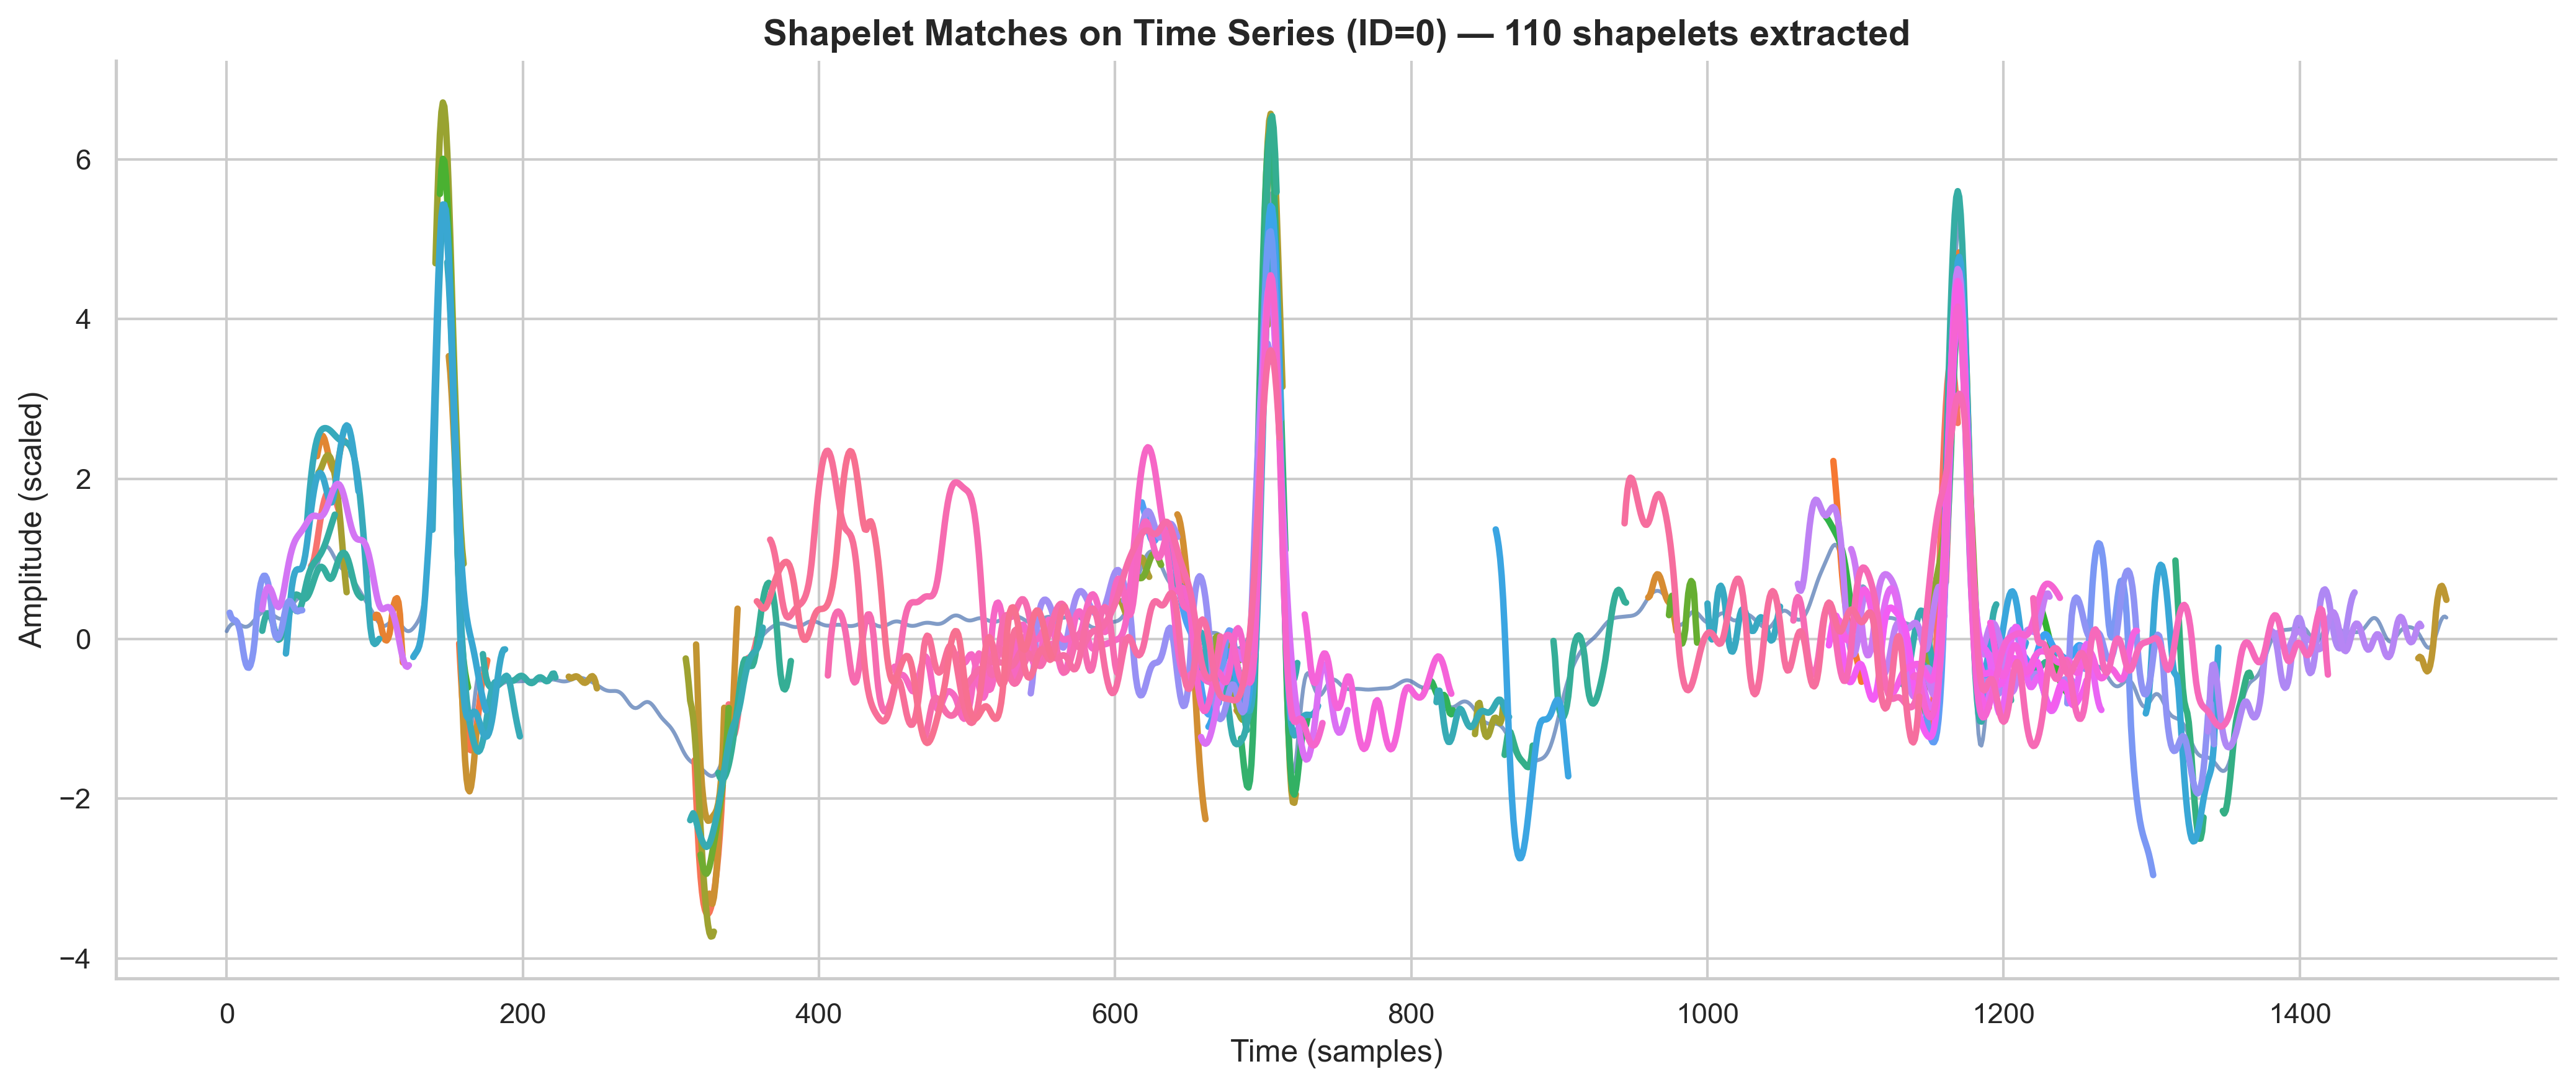

In [145]:
import seaborn as sns
import matplotlib.pyplot as plt

ts_id = 0
n_shapelets = sum(shapelet_sizes.values())

# Set seaborn style
sns.set_theme(style="whitegrid")

fig, ax = plt.subplots(figsize=(14, 6), dpi=300)

# Plot the original time series
ax.plot(X[ts_id].ravel(), label='ECG Signal', color=sns.color_palette("deep")[0], alpha=0.7)

# Plot each shapelet at its matched location
colors = sns.color_palette("husl", n_colors=len(shp_clf.shapelets_))
for idx_shp, shp in enumerate(shp_clf.shapelets_):
    t0 = predicted_locations[ts_id, idx_shp]
    ax.plot(np.arange(t0, t0 + len(shp)), shp.ravel(), 
            linewidth=2.5, color=colors[idx_shp], 
            label=f'Shapelet {idx_shp + 1} (len={len(shp)})')

ax.set_title(f'Shapelet Matches on Time Series (ID={ts_id}) — {n_shapelets} shapelets extracted', 
             fontsize=14, fontweight='bold')
ax.set_xlabel('Time (samples)', fontsize=12)
ax.set_ylabel('Amplitude (scaled)', fontsize=12)


sns.despine()
plt.tight_layout()
plt.show()